In [1]:
import pandas as pd

df = pd.read_csv("../data/cardio_train.csv", sep=";")
df.head()



,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df.drop("id", axis=1, inplace=True)


In [4]:
df["age"] = (df["age"] / 365).round().astype(int)


In [5]:
df.head()


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,48,1,156,56.0,100,60,1,1,0,0,0,0


In [6]:
df = df[df["ap_lo"] < df["ap_hi"]]
df = df[(df["ap_hi"] > 50) & (df["ap_hi"] < 250)]
df = df[(df["ap_lo"] > 30) & (df["ap_lo"] < 200)]


In [7]:
df = df[(df["height"] > 120) & (df["height"] < 220)]
df = df[(df["weight"] > 30) & (df["weight"] < 200)]


In [8]:
df["bmi"] = df["weight"] / ((df["height"]/100) ** 2)


In [9]:
X = df.drop("cardio", axis=1)
y = df["cardio"]


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [11]:
df.shape


(68579, 13)

In [18]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight= (len(y_train[y_train==0]) / len(y_train[y_train==1])),
    random_state=42,
    eval_metric="logloss"
)



In [19]:
model.fit(X_train, y_train)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [20]:
y_pred = model.predict(X_test)


In [23]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
accuracy


0.7387722368037328

In [16]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.72      0.79      0.75      6946
           1       0.76      0.69      0.72      6770

    accuracy                           0.74     13716
   macro avg       0.74      0.74      0.74     13716
weighted avg       0.74      0.74      0.74     13716



In [17]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
cm


array([[5460, 1486],
       [2113, 4657]], dtype=int64)

In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)
from xgboost import XGBClassifier
import joblib

# 1) VERİYİ YENİDEN YÜKLE
df = pd.read_csv("../data/cardio_train.csv", sep=";")

# 2) GEREKSİZ SÜTUNU SİL (id)
df.drop("id", axis=1, inplace=True)

# 3) YAŞI GÜNDEN YILA ÇEVİR
df["age"] = (df["age"] / 365).round().astype(int)

# 4) TANSİYON TEMİZLİĞİ
df = df[df["ap_lo"] < df["ap_hi"]]
df = df[(df["ap_hi"] > 50) & (df["ap_hi"] < 250)]
df = df[(df["ap_lo"] > 30) & (df["ap_lo"] < 200)]

# 5) BOY / KİLO TEMİZLİĞİ
df = df[(df["height"] > 120) & (df["height"] < 220)]
df = df[(df["weight"] > 30) & (df["weight"] < 200)]

# 6) BMI ÖZELLİĞİNİ EKLE
df["bmi"] = df["weight"] / ((df["height"] / 100) ** 2)

# 7) ÖZELLİKLER VE HEDEF
X = df.drop("cardio", axis=1)
y = df["cardio"]

# 8) TRAIN / TEST AYIR
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Veri boyutu:", df.shape)

# 9) XGBoost MODELİ (bir tık iyileştirilmiş ayarlar)
scale_pos = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos,
    random_state=42,
    eval_metric="logloss"
)

# 10) MODELİ EĞİT
model.fit(X_train, y_train)

# 11) TAHMİN VE METRİKLER
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)

print("Accuracy:", acc)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", report)
print("ROC AUC:", auc_score)

# 12) MODELİ KAYDET
os.makedirs("../models", exist_ok=True)
joblib.dump(model, "../models/xgb_model.pkl")

print("\nModel '../models/xgb_model.pkl' dosyasına kaydedildi.")


Veri boyutu: (68579, 13)
Accuracy: 0.7387722368037328

Confusion Matrix:
 [[5442 1504]
 [2079 4691]]

Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.78      0.75      6946
           1       0.76      0.69      0.72      6770

    accuracy                           0.74     13716
   macro avg       0.74      0.74      0.74     13716
weighted avg       0.74      0.74      0.74     13716

ROC AUC: 0.8042534921217528

Model '../models/xgb_model.pkl' dosyasına kaydedildi.


In [1]:
1+1

2

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# Burada df, X, y, X_train, X_test, y_train, y_test hazır olmalı
# (zaten önceden pipeline'ı çalıştırmıştık)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1]),
        random_state=42,
        eval_metric="logloss"
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append((name, acc, f1))

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1-Score"]).sort_values(by="Accuracy", ascending=False)

print(results_df)


NameError: name 'y_train' is not defined

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# 1) VERİYİ YÜKLE
df = pd.read_csv("../data/cardio_train.csv", sep=";")

# 2) GEREKSİZ SÜTUN
df.drop("id", axis=1, inplace=True)

# 3) YAŞI YILA ÇEVİR
df["age"] = (df["age"] / 365).round().astype(int)

# 4) HATALI TANSİYONLARI TEMİZLE
df = df[df["ap_lo"] < df["ap_hi"]]
df = df[(df["ap_hi"] > 50) & (df["ap_hi"] < 250)]
df = df[(df["ap_lo"] > 30) & (df["ap_lo"] < 200)]

# 5) BOY - KİLO TEMİZLE
df = df[(df["height"] > 120) & (df["height"] < 220)]
df = df[(df["weight"] > 30) & (df["weight"] < 200)]

# 6) BMI EKLE
df["bmi"] = df["weight"] / ((df["height"] / 100) ** 2)

# 7) X - y AYIR
X = df.drop("cardio", axis=1)
y = df["cardio"]

# 8) TRAIN / TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Hazır! X_train:", X_train.shape, "y_train:", y_train.shape)


Hazır! X_train: (54863, 12) y_train: (54863,)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1]),
        random_state=42,
        eval_metric="logloss"
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append((name, acc, f1))

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1-Score"]).sort_values(by="Accuracy", ascending=False)

print(results_df)


C:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


                 Model  Accuracy  F1-Score
3              XGBoost  0.738772  0.723641
2    Gradient Boosting  0.737241  0.722214
0  Logistic Regression  0.729878  0.709662
1        Random Forest  0.709682  0.702747


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1]),
        random_state=42,
        eval_metric="logloss"
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append((name, acc, f1))

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1-Score"]).sort_values(by="Accuracy", ascending=False)

print(results_df)


                 Model  Accuracy  F1-Score
3              XGBoost  0.738772  0.723641
2    Gradient Boosting  0.737241  0.722214
0  Logistic Regression  0.729367  0.708771
1        Random Forest  0.709682  0.702747


In [6]:
df.shape


(68579, 13)

In [ ]:
import shap
import matplotlib.pyplot as plt

shap.initjs()

explainer = shap.TreeExplainer(model)

sample_X = X_test.sample(200, random_state=42)

shap_values = explainer(sample_X)

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.show()



In [7]:
import shap
import matplotlib.pyplot as plt

shap.initjs()

explainer = shap.TreeExplainer(model)

sample_X = X_test.sample(200, random_state=42)

shap_values = explainer(sample_X)

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.show()



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel\kernelapp.py", line 758,

AttributeError: _ARRAY_API not found

NameError: name 'model' is not defined

In [8]:
import shap
import matplotlib.pyplot as plt

shap.initjs()

explainer = shap.TreeExplainer(model)

sample_X = X_test.sample(200, random_state=42)

shap_values = explainer(sample_X)

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.show()


NameError: name 'model' is not defined

In [9]:
import shap
import matplotlib.pyplot as plt

shap.initjs()

explainer = shap.TreeExplainer(Model)

sample_X = X_test.sample(200, random_state=42)

shap_values = explainer(sample_X)

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.show()


NameError: name 'Model' is not defined

In [10]:
print(globals().keys())


dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__session__', 'platform', 'sys', 'original_ps1', 'is_wsl', 'REPLHooks', 'get_last_command', 'PS1', '_i', '_ii', '_iii', '_i1', '_1', '_i2', 'LogisticRegression', 'RandomForestClassifier', 'GradientBoostingClassifier', 'XGBClassifier', 'accuracy_score', 'f1_score', '_i3', 'pd', 'np', 'train_test_split', 'df', 'X', 'y', 'X_train', 'X_test', 'y_train', 'y_test', '_i4', 'models', 'results', 'name', 'clf', 'y_pred', 'acc', 'f1', 'results_df', '_i5', '_i6', '_6', '_i7', 'shap', 'plt', '_i8', '_i9', '_i10'])


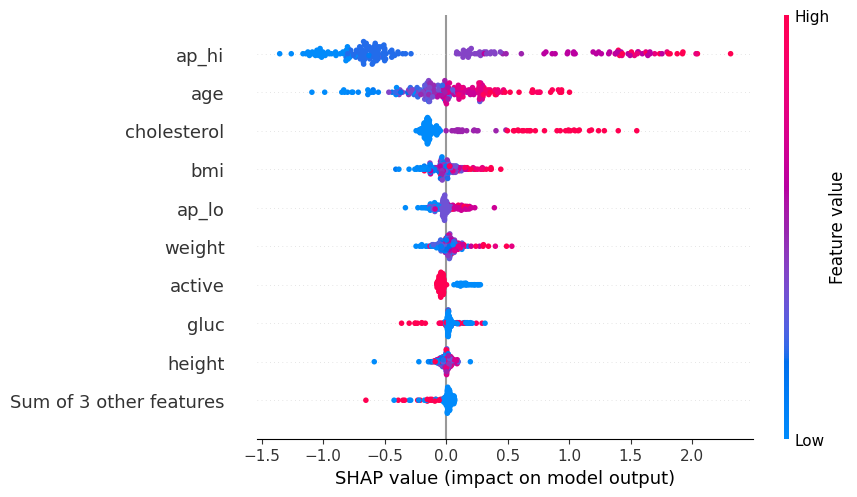

In [11]:
import shap
import matplotlib.pyplot as plt

shap.initjs()

# 1) Açıklamak istediğin modeli seç
model = models["XGBoost"]   # İstersen "Random Forest" ya da "Gradient Boosting" yaz

# 2) TreeExplainer oluştur
explainer = shap.TreeExplainer(model)

# 3) Test setinden bir örnek al
sample_X = X_test.sample(200, random_state=42)

# 4) SHAP değerlerini hesapla
shap_values = explainer(sample_X)

# 5) Beeswarm grafiğini çiz
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.show()


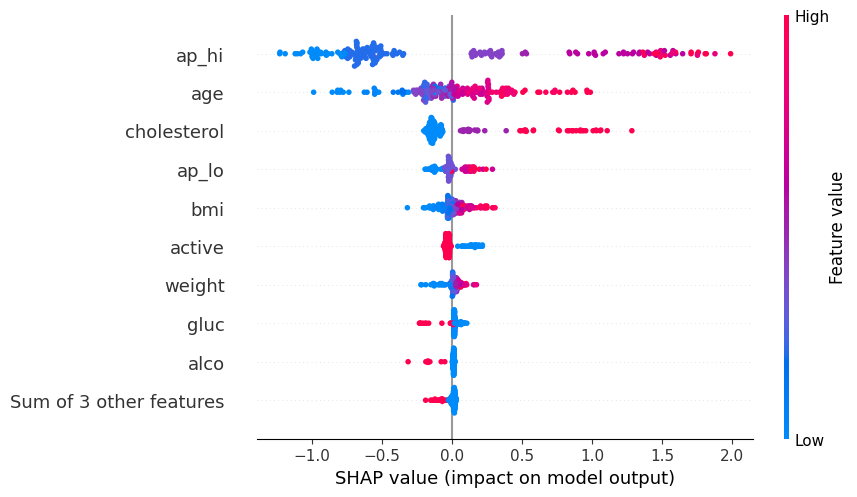

In [12]:
import shap
import matplotlib.pyplot as plt

shap.initjs()

# 1) Açıklamak istediğin modeli seç
model = models["Gradient Boosting"]   # İstersen "Random Forest" ya da "Gradient Boosting" yaz

# 2) TreeExplainer oluştur
explainer = shap.TreeExplainer(model)

# 3) Test setinden bir örnek al
sample_X = X_test.sample(200, random_state=42)

# 4) SHAP değerlerini hesapla
shap_values = explainer(sample_X)

# 5) Beeswarm grafiğini çiz
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.show()


In [13]:
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import shap
import joblib
import pandas as pd
import numpy as np

# df, X, y zaten hazırlanmış olsun
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({"Model": name, "Accuracy": acc, "F1": f1})

results_df = pd.DataFrame(results)
print(results_df)


               Model  Accuracy        F1
0            XGBoost  0.727982  0.716166
1  Gradient Boosting  0.727909  0.715809
2           AdaBoost  0.722076  0.695430


In [14]:
explainer_dict = {}
for name, clf in models.items():
    explainer_dict[name] = shap.TreeExplainer(clf)

# Modelleri ve explainers'ı diske kaydet
joblib.dump(models, "models.pkl")
joblib.dump(explainer_dict, "explainers.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")


InvalidModelError: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>

In [15]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# df, X, y zaten hazırlanmış durumda olsun
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=42
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({"Model": name, "Accuracy": acc, "F1": f1})

results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,F1
0,XGBoost,0.727982,0.716166
1,Gradient Boosting,0.727909,0.715809
2,Random Forest,0.704579,0.700340


In [16]:
import shap
import joblib

explainer_dict = {}
for name, clf in models.items():
    explainer_dict[name] = shap.TreeExplainer(clf)

# Modelleri ve explainers'ı diske kaydet
joblib.dump(models, "models.pkl")
joblib.dump(explainer_dict, "explainers.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")


['feature_names.pkl']

In [17]:
print("models var mı:", "models" in globals())
print("explainer_dict var mı:", "explainer_dict" in globals())


models var mı: True
explainer_dict var mı: True


In [18]:
import joblib
import os

# Şu an hangi klasördeyiz, görelim:
print("Çalışılan klasör:", os.getcwd())

# 3 dosyayı da kaydet
joblib.dump(models, "models.pkl")
joblib.dump(explainer_dict, "explainers.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")

# Klasörde neler var, kontrol edelim:
print(os.listdir())


Çalışılan klasör: C:\Users\HP\OneDrive\Belgeler\GitHub\cardiovascular-disease_-project\notebooks
['.ipynb_checkpoints', 'analysis.ipynb', 'explainers.pkl', 'feature_names.pkl', 'models.pkl']


In [ ]:
# BOOSTING MODELLERİ - Random Forest yerine LightGBM ve AdaBoost
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import shap
import joblib
import pandas as pd
import numpy as np

# Veri hazırsa devam
print("✅ Veri hazırlanıyor...")

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# BOOSTING MODELLERİ (Random Forest YOK!)
models = {
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        verbosity=0
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        verbose=0
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.8,
        random_state=42
    )
}

print("\n🔄 Modeller eğitiliyor...\n")

results = []

for name, clf in models.items():
    print(f"   ⏳ {name} eğitiliyor...")
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    
    results.append({
        "Model": name, 
        "Accuracy": round(acc, 4), 
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })
    
    print(f"   ✅ {name} OK! (Acc: {acc:.4f}, F1: {f1:.4f}, AUC: {auc:.4f})")

# Sonuçları göster
results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
print("\n📊 PERFORMANS SONUÇLARI:")
print(results_df)


In [ ]:
# SHAP Explainer'ları oluştur ve kaydet
print("\n🧠 SHAP Explainer'lar oluşturuluyor...")

explainer_dict = {}

for name, clf in models.items():
    print(f"   🔍 {name} için explainer oluşturuluyor...")
    explainer_dict[name] = shap.TreeExplainer(clf)
    print(f"   ✅ {name} explainer hazır!")

# Dosyaları ana dizine kaydet
print("\n💾 Dosyalar kaydediliyor...")

joblib.dump(models, "../models.pkl")
print("   ✅ models.pkl kaydedildi")

joblib.dump(explainer_dict, "../explainers.pkl")
print("   ✅ explainers.pkl kaydedildi")

joblib.dump(list(X.columns), "../feature_names.pkl")
print("   ✅ feature_names.pkl kaydedildi")

print("\n🎉 TÜM İŞLEMLER TAMAMLANDI!")
print("\n📌 Kaydedilen Boosting Modelleri:")
for name in models.keys():
    print(f"   • {name}")
print("\n🚀 Artık 'streamlit run app.py' ile uygulamayı çalıştırabilirsiniz!")
